# TS5: Estimación espectral: Ancho de banda de señales reales
## Alumno: Matías Carbajal
## Materia: Análisis y Procesamiento de Señales (APS)
## Carrera: Ingeniería Telecomunicaciones
## Fecha: 25 de septiembre de 2026

# Introducción teórica

El análisis espectral es una herramienta fundamental para caracterizar el contenido en frecuencia de una señal. Resulta primordial identificar entre señales de energía y señales de potencia, ya que este criterio determina el tipo de análisis espectral a realizar.

Una **señal de energía** es aquella que posee energía finita y potencia promedio nula. Su energía total se define como:

$$E = \sum_{n=-\infty}^{\infty} |x[n]|^2 \tag{1}$$

Estas señales suelen ser aperiódicas y de duración finita o sumables en energía (como pulsos e impulsos).

Por otro lado, una **señal de potencia** posee potencia promedio finita (no nula) y energía infinita. Se define como:

$$P = \lim_{N \to \infty} \frac{1}{2N+1} \sum_{n=-N}^{N} |x[n]|^2 \tag{2}$$

Estas señales suelen ser periódicas o estacionarias en el tiempo, como las señales senoidales o el ruido blanco estocástico.

---

### Densidad Espectral de Potencia (DSP / PSD)

La Densidad Espectral de Potencia describe cómo se distribuye la potencia de una señal en función de la frecuencia, permitiendo identificar los componentes energéticos dominantes y determinar el ancho de banda efectivo del sistema o señal bajo estudio.

A través del **Teorema de Wiener-Khinchin**, la DSP se relaciona con la función de autocorrelación $R_x(\tau)$ mediante la Transformada de Fourier:

$$S_x(f) = \mathcal{F}\{R_x(\tau)\} = \int_{-\infty}^{\infty} R_x(\tau) e^{-j 2\pi f \tau} \, d\tau \tag{3}$$

Para estimar la densidad espectral de potencia a partir de señales discretas y finitas existen diversos métodos no paramétricos. Entre los más utilizados se encuentran los métodos de **Welch** y de **Blackman-Tukey**.

---

### Método de Welch

Es un estimador de la DSP que busca reducir drásticamente la varianza de la estimación. Consiste en:
1. Dividir la señal de $N$ muestras en $K$ segmentos de longitud $L$ (con o sin solapamiento).
2. Aplicar una ventana de ponderación $w[n]$ (Hamming, Hann, etc.) a cada segmento.
3. Calcular su Transformada Rápida de Fourier (FFT) al cuadrado (periodograma modificado).
4. Promediar las potencias resultantes:

$$S_x(f) = \frac{1}{K} \sum_{k=1}^{K} \frac{1}{U} \left| \mathrm{FFT}\{ w[n] \cdot x_k[n] \} \right|^2 \tag{4}$$

Donde $K$ es el número de segmentos, $w[n]$ es la ventana aplicada y $U = \sum_{n=0}^{L-1} w^2[n]$ es la constante de normalización de energía de la ventana. Este método reduce la varianza en orden proporcional a la cantidad de segmentos promediados, a expensas de sacrificar resolución espectral debido al menor tamaño de bloque $L < N$. Adicionalmente, puede aplicarse *zero-padding* para interpolar la grilla frecuencial de la DFT.

---

### Método de Blackman-Tukey

El método de Blackman-Tukey se basa en calcular primero la autocorrelación muestral $R_{xx}[m]$ a partir de toda la longitud del registro, para luego truncarla y suavizarla mediante una ventana simétrica $w[m]$ de longitud $2M+1$ (con $M \ll N$).

La estimación de la DSP se obtiene mediante la Transformada de Fourier discreta de la autocorrelación enventanada:

$$S_x(f) = \sum_{m=-M}^{M} w[m] R_{xx}[m] e^{-j 2\pi f m} \tag{5}$$

Este método atenúa los retardos lejanos ($m \to N$) que poseen pocas muestras de solapamiento y gran dispersión estocástica, reduciendo la varianza en proporción a $M/N$. Presenta menor sesgo que Welch frente a señales con soporte extendido, resultando idóneo para señales estacionarias con mediciones prolongadas.

---

### Ancho de Banda

El ancho de banda de una señal define el rango de frecuencias donde se concentra la mayor parte de su potencia. Se emplean distintos criterios analíticos según el tipo de aplicación:

* **Ancho de banda a $-3\text{ dB}$ (potencia media):**

  $$B = f_2 - f_1 \tag{6}$$

  donde los puntos de corte $f_1$ y $f_2$ satisfacen:

  $$S_x(f_1) = S_x(f_2) = \frac{S_{x,\mathrm{max}}}{2} \tag{7}$$

* **Ancho de banda efectivo (o equivalente de ruido):**

  $$B_{\mathrm{ef}} = \frac{\int_{0}^{\infty} S_x(f) \, df}{S_{x,\mathrm{max}}} \tag{8}$$

En la práctica, el ancho de banda determina la resolución temporal/frecuencial, la tasa de transmisión admisible del canal y la región del espectro relevante para el procesamiento o filtrado de la señal.

analisis desarrollo

In [2]:
import numpy as np
from scipy import signal as sig
import matplotlib.pyplot as plt
import scipy.io as sio
from numpy.fft import fft
#cte universales 
fs_ecg = 1000 # Hz
fs_ppg = 400 # Hz

#funciones de ingreso
#Ecg sin ruido 
ecg_one_lead = np.load('ecg_sin_ruido.npy')
Necg=ecg_one_lead.shape[0]
#La cucaracha
fs_audio, wav_data = sio.wavfile.read('la cucaracha.wav')
Ncuca=wav_data.shape[0]
#PPG
ppg = np.load('ppg_sin_ruido.npy')
Nppg=ppg.shape[0]

### Elección de Ventanas y Segmentación

Para procesar estas señales no se aplican las ecuaciones de la DSP de forma directa; primero hay que elegir la ventana adecuada:

* **Para el método de Welch:** se usa la ventana de **Hann** para todas las señales (ECG, PPG y audio).
* **Para el método de Blackman-Tukey:** se utiliza la ventana de **Bartlett** (ventana triangular).

Una vez fijadas las ventanas, se define la cantidad de promedios (o segmentos) para Welch. Para calibrar este valor, se usa como guía el espectro de Blackman-Tukey, buscando un balance adecuado entre la resolución en frecuencia y la suavidad del gráfico.

Text(0.5, 1.0, 'Figura[1]: ECG - Blackman-Tukey')

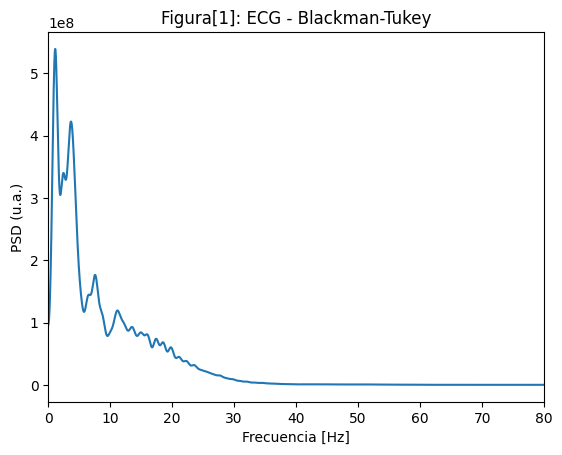

In [3]:
#blackman-tuky ECG 
#Hago autocorrelacion
Ecgxx = ecg_one_lead - np.mean(ecg_one_lead)
Recg=sig.correlate(Ecgxx,Ecgxx, mode='full')/Necg
lagsecg = np.arange(-Necg+1, Necg)
centerecg = len(Recg)//2
M= int(1.0 * fs_ecg)
Recg_seg = Recg[centerecg-M : centerecg+M+1]
#ventaneo por la ventana triangular
Recgventaneada=Recg_seg*sig.windows.bartlett(2*M+1)   
#le calculo la FFT
FFTECG=fft(Recgventaneada,axis=0, n=4*Necg)

half = 4*Necg//2
fEcg = np.linspace(0, fs_ecg/2, half, endpoint=False)

plt.figure()
plt.plot(fEcg, np.abs(FFTECG[:half]))   
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("PSD (u.a.)")
plt.xlim([0, 80])                 
plt.title("Figura[1]: ECG - Blackman-Tukey")

Al analizar la estimación espectral de la Figura [1], se observa que el aspecto más relevante es conservar la resolución de las componentes armónicas principales del espectro del ECG (entre 0.5 Hz y 30 Hz). 

El objetivo principal es definir un número adecuado de promedios $K$ mediante el **método de Welch** que permita reducir la varianza estadística del estimador sin perder resolución espectral ni fusionar los picos fundamentales de la señal. 

Para evaluar este compromiso (*trade-off*), se varió la cantidad de segmentos entre $K \in \{15, 25, 35\}$ solapados al 50% con ventana de Hann. Adicionalmente, se aplicó *zero-padding* en el dominio frecuencial extendiendo la longitud de la FFT a $N_{\mathrm{fft}} > 1000$ puntos por bloque. Esto permite interpolar la grilla espectral ($\Delta f_{\mathrm{pad}} = f_s / N_{\mathrm{fft}}$), obteniendo una representación continua y suave de la densidad espectral de potencia sin alterar la información temporal original de los bloques.

cantidad: 2000


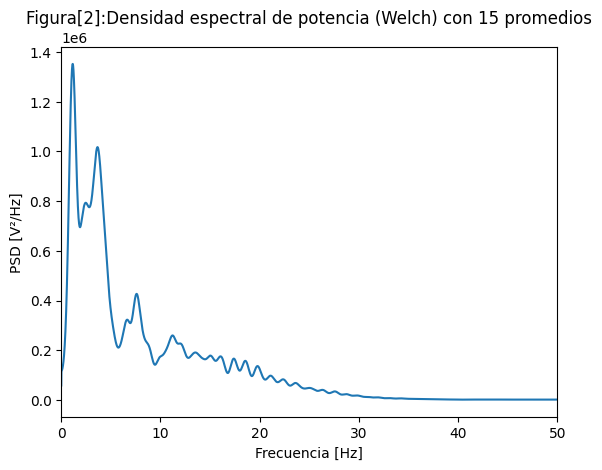

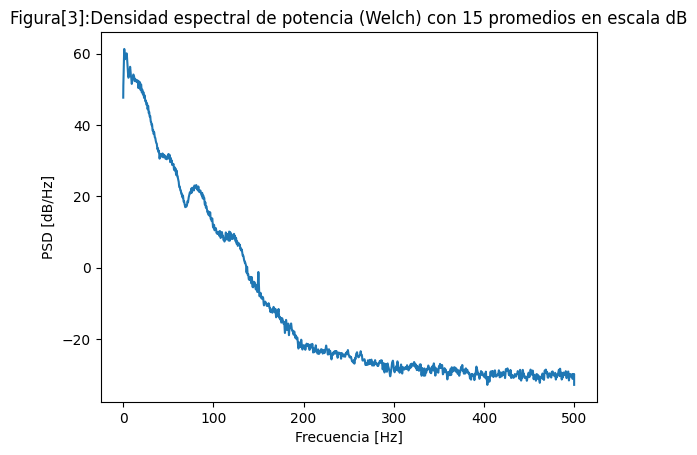

In [4]:
cpECG=15 #cantidad de promedio
npersegECG=ecg_one_lead.shape[0] // cpECG
print("cantidad:",npersegECG)
nfft=100*npersegECG
win='hann'
tWECGSR_ECG,WECGSR_ECG=sig.welch(ecg_one_lead,fs=fs_ecg,window=win,nperseg=npersegECG,nfft=nfft)
plt.figure()
plt.plot(tWECGSR_ECG,(WECGSR_ECG))
plt.xlim(0,50)
plt.title("Figura[2]:Densidad espectral de potencia (Welch) con 15 promedios" )
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("PSD [V²/Hz]")
plt.show()
plt.figure()
plt.plot(tWECGSR_ECG,10*np.log10(WECGSR_ECG))
plt.title("Figura[3]:Densidad espectral de potencia (Welch) con 15 promedios en escala dB")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("PSD [dB/Hz]")
plt.show()

cantidad: 1200


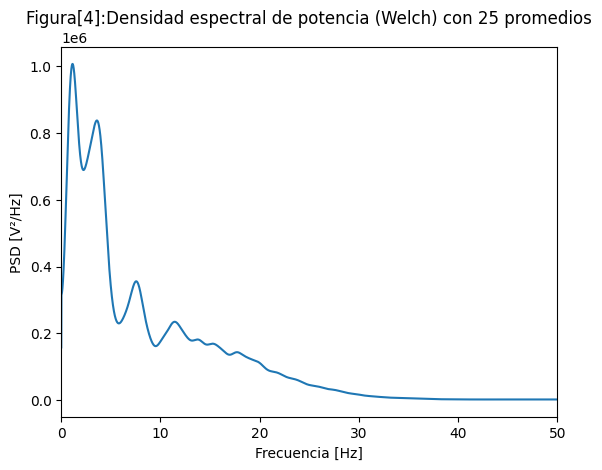

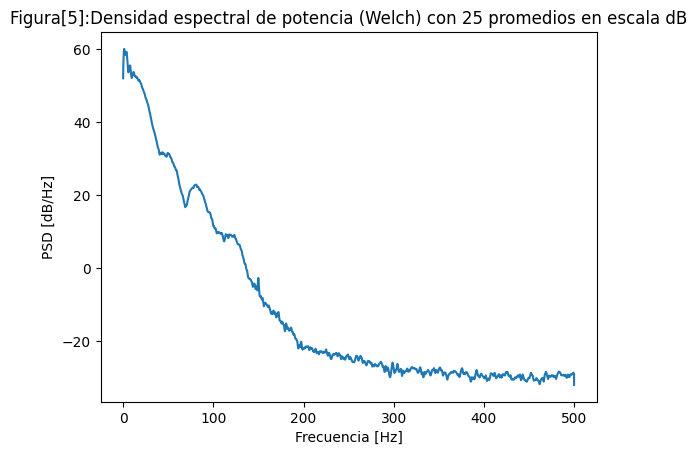

In [5]:
cpECG=25 #cantidad de promedio
npersegECG=ecg_one_lead.shape[0] // cpECG
print("cantidad:",npersegECG)
nfft=100*npersegECG
win='hann'
tWECGSR_ECG,WECGSR_ECG=sig.welch(ecg_one_lead,fs=fs_ecg,window=win,nperseg=npersegECG,nfft=nfft)
plt.figure()
plt.plot(tWECGSR_ECG,(WECGSR_ECG))
plt.xlim(0,50)
plt.title("Figura[4]:Densidad espectral de potencia (Welch) con 25 promedios")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("PSD [V²/Hz]")
plt.show()
plt.figure()
plt.plot(tWECGSR_ECG,10*np.log10(WECGSR_ECG))
plt.title("Figura[5]:Densidad espectral de potencia (Welch) con 25 promedios en escala dB")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("PSD [dB/Hz]")
plt.show()

cantidad: 857


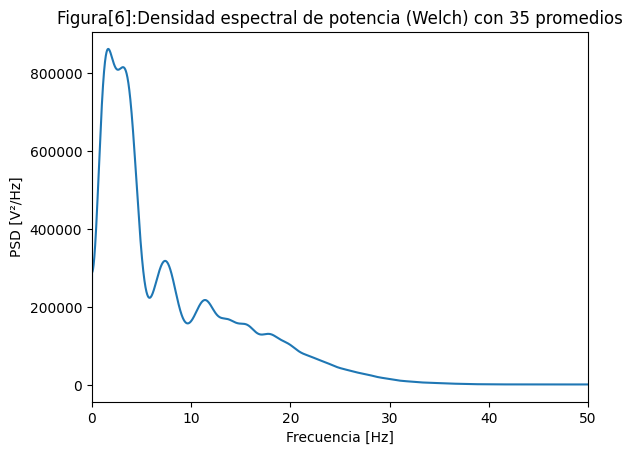

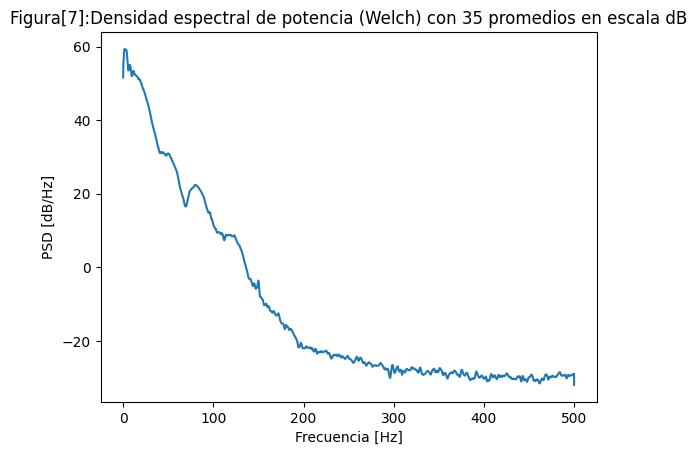

In [6]:
cpECG=35 #cantidad de promedio
npersegECG=ecg_one_lead.shape[0] // cpECG
print("cantidad:",npersegECG)
nfft=100*npersegECG
win='hann'
tWECGSR_ECG,WECGSR_ECG=sig.welch(ecg_one_lead,fs=fs_ecg,window=win,nperseg=npersegECG,nfft=nfft)
plt.figure()
plt.plot(tWECGSR_ECG,(WECGSR_ECG))
plt.xlim(0,50)
plt.title("Figura[6]:Densidad espectral de potencia (Welch) con 35 promedios")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("PSD [V²/Hz]")
plt.show()
plt.figure()
plt.plot(tWECGSR_ECG,10*np.log10(WECGSR_ECG))
plt.title("Figura[7]:Densidad espectral de potencia (Welch) con 35 promedios en escala dB")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("PSD [dB/Hz]")
plt.show()

Al comparar las Figuras [1], [2], [4] y [6], se observa que la Figura [2] ($K = 15$) presenta una morfología espectral más similar a la estimación por Blackman-Tukey de la Figura [1]. Esto resulta coherente con la teoría: al incrementar la cantidad de promedios $M$ en el método de Welch, las componentes no correlacionadas (como el ruido estocástico) se atenúan progresivamente, reduciendo la varianza del estimador en proporción a $1/M$.

Asimismo, en las Figuras [3], [5] y [7], muestra un piso de ruido cada vez más estable y libre de fluctuaciones erráticas. Este comportamiento refleja el compromiso (*trade-off*) del método de Welch: 
1. **Reducción de varianza:** El promedio de los $M$ periodogramas modificados estabiliza la estimación ($\text{Var} \propto \frac{9}{16M}$).
2. **Limitación de resolución:** Al incrementar $M$, el tamaño de bloque temporal $L$ disminuye ($L \approx N/M$), lo que ensancha el lóbulo principal de la ventana ($\Delta f \approx f_s / L$) e incrementa levemente el sesgo local sobre picos estrechos.

Para verificar esta propiedad sobre señales variantes en el tiempo, se realizará la estimación espectral sobre el audio del silbido ("La Cucaracha"), variando la cantidad de promedios en $M \in \{10, 20, 30\}$ solapados al 50%. Se prevé observar el mismo comportamiento de suavizado del piso de ruido a costa de un leve ensanchamiento en las componentes armónicas de la melodía.

Text(0.5, 1.0, 'Figura[8]: La cucaracha - Blackman-Tukey')

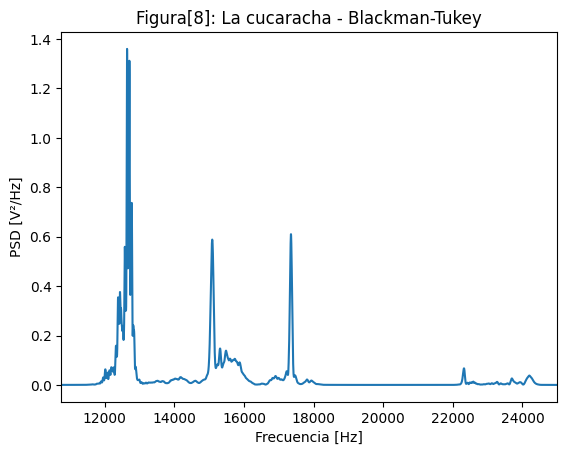

In [14]:
#Blackman-turkey 
#Hago autocorrelacion
y = wav_data
if y.ndim > 1:
    y = y[:, 0]
y = y.astype(float) - np.mean(y)

Ncu = len(y)
Rcu = sig.correlate(y, y, mode='full') / Ncu          # biased
center_cu = len(Rcu) // 2

# elegir M en tiempo -> 0.5 s (ejemplo razonable para audio)
M_des_cu = int(0.5 * fs_audio)
# limitar M por los datos
M_cu = min(M_des_cu, Ncu-1, center_cu, len(Rcu) - center_cu - 1)

Rcu_seg = Rcu[center_cu - M_cu : center_cu + M_cu + 1]
w_cu = sig.windows.bartlett(len(Rcu_seg))
Rcu_win = Rcu_seg * w_cu

nfft_cu = 4 * Ncu
PSD_BT_cu = np.abs(np.fft.rfft(Rcu_win, n=nfft_cu))

plt.figure()
plt.plot(np.abs(PSD_BT_cu))
plt.xlim(10750,25000)
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("PSD [V²/Hz]")
plt.title('Figura[8]: La cucaracha - Blackman-Tukey')

14400


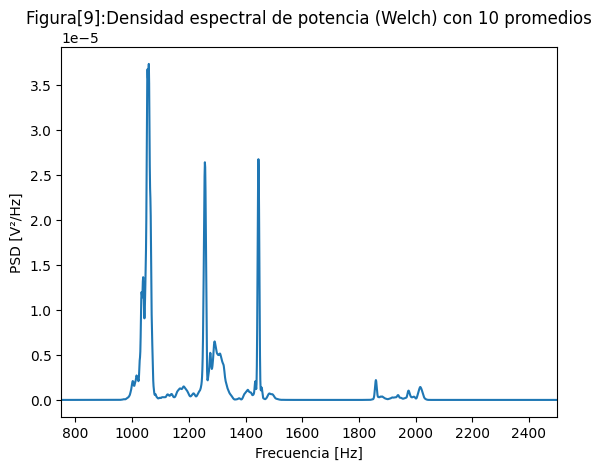

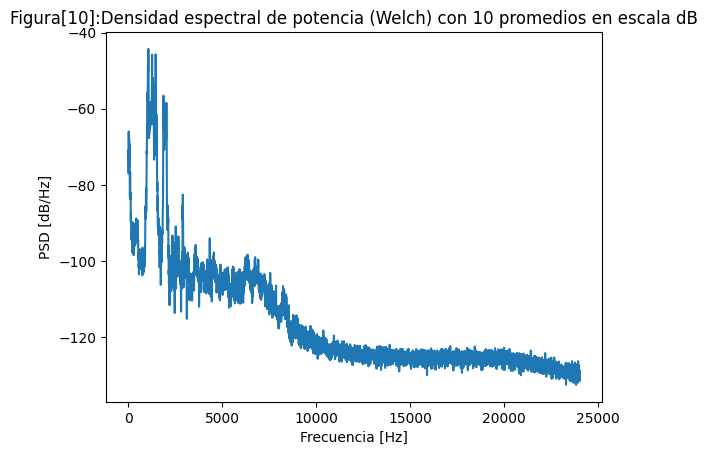

In [15]:
cpcucaracha=10 #cantidad de promedio
npersegcucaracha=wav_data.shape[0] // cpcucaracha
print(npersegcucaracha)
nfftcucaracha=3*npersegcucaracha
win='hann'
tWCuca,WCuca=sig.welch(wav_data,fs=fs_audio,window=win,nperseg=npersegcucaracha,nfft=nfftcucaracha)
plt.figure()
plt.plot(tWCuca,(WCuca))
plt.xlim(750,2500)
plt.title("Figura[9]:Densidad espectral de potencia (Welch) con 10 promedios")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("PSD [V²/Hz]")
plt.show()
plt.figure()
plt.plot(tWCuca,10*np.log10(WCuca))
plt.title("Figura[10]:Densidad espectral de potencia (Welch) con 10 promedios en escala dB")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("PSD [dB/Hz]")
plt.show() 

7200


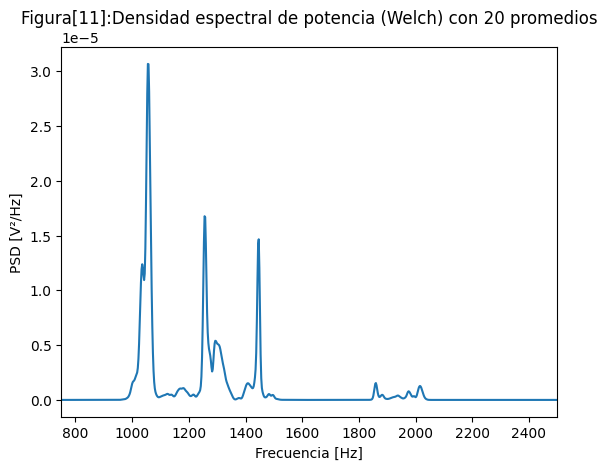

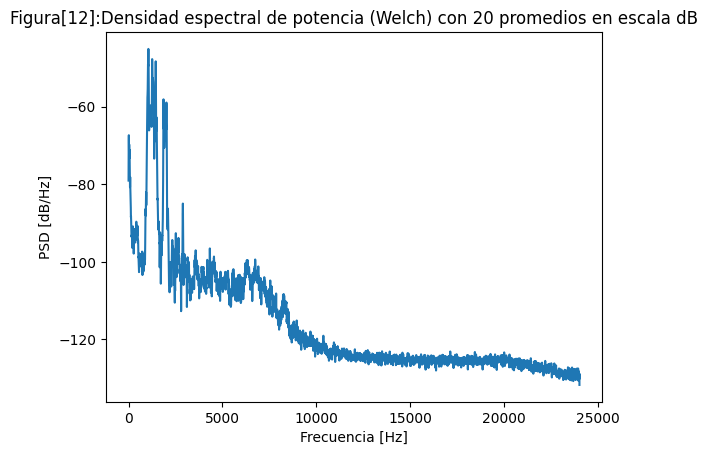

In [16]:
cpcucaracha=20 #cantidad de promedio
npersegcucaracha=wav_data.shape[0] // cpcucaracha
print(npersegcucaracha)
nfftcucaracha=3*npersegcucaracha
win='hann'
tWCuca,WCuca=sig.welch(wav_data,fs=fs_audio,window=win,nperseg=npersegcucaracha,nfft=nfftcucaracha)
plt.figure()
plt.plot(tWCuca,(WCuca))
plt.xlim(750,2500)
plt.title("Figura[11]:Densidad espectral de potencia (Welch) con 20 promedios")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("PSD [V²/Hz]")
plt.show()
plt.figure()
plt.plot(tWCuca,10*np.log10(WCuca))
plt.title("Figura[12]:Densidad espectral de potencia (Welch) con 20 promedios en escala dB")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("PSD [dB/Hz]")
plt.show() 

4800


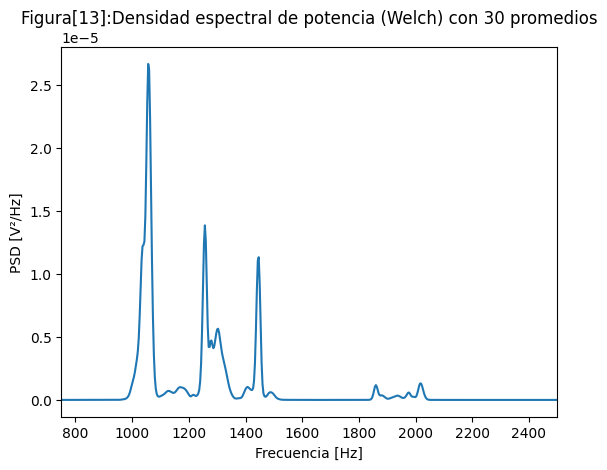

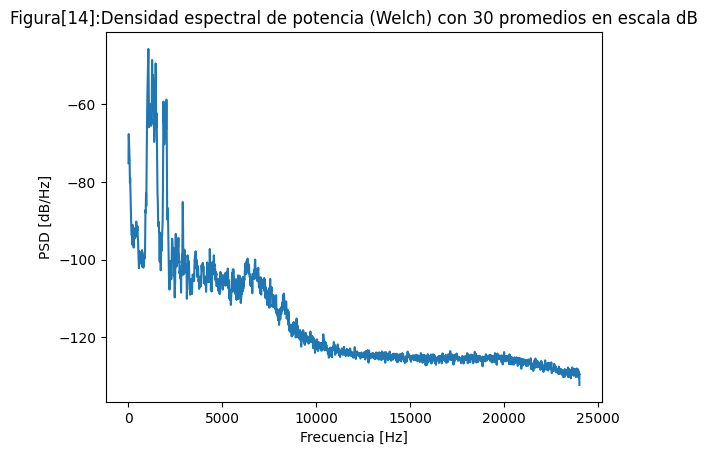

In [17]:
cpcucaracha=30 #cantidad de promedio
npersegcucaracha=wav_data.shape[0] // cpcucaracha
print(npersegcucaracha)
nfftcucaracha=3*npersegcucaracha
win='hann'
tWCuca,WCuca=sig.welch(wav_data,fs=fs_audio,window=win,nperseg=npersegcucaracha,nfft=nfftcucaracha)
plt.figure()
plt.plot(tWCuca,(WCuca))
plt.xlim(750,2500)
plt.title("Figura[13]:Densidad espectral de potencia (Welch) con 30 promedios")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("PSD [V²/Hz]")
plt.show()
plt.figure()
plt.plot(tWCuca,10*np.log10(WCuca))
plt.title("Figura[14]:Densidad espectral de potencia (Welch) con 30 promedios en escala dB")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("PSD [dB/Hz]")
plt.show() 

### Elección de Ventanas y Selección de Promedios (Welch vs. Blackman-Tukey)

* **Para el método de Welch:** Se utiliza la ventana de **Hann** para todas las señales (ECG, PPG y audio), ya que reduce significativamente el desparramo espectral (*leakage*) manteniendo un buen equilibrio en el ancho del lóbulo principal.
* **Para el método de Blackman-Tukey:** Se adopta la ventana de **Bartlett** (triangular) sobre la función de autocorrelación, lo que garantiza que la estimación espectral sea estrictamente no negativa.

#### Selección del número de promedios en Welch
El número óptimo de promedios $K$ depende fuertemente del contenido frecuencial de la señal de entrada. Para determinarlo, se utilizó el espectro obtenido por Blackman-Tukey como patrón de referencia visual de la morfología "verdadera" de la señal:

* Se buscó incrementar $K$ para reducir la varianza estadística del piso de ruido ($\text{Var} \propto 1/K$) sin reducir en exceso el tamaño de bloque $L$, evitando así el ensanchamiento (*smearing*) o la fusión de los picos armónicos principales.
* Para la señal de **PPG**, se verificó que un rango de **20 a 25 promedios** ofrece un compromiso óptimo, eliminando el ruido de alta frecuencia.

Text(0.5, 1.0, 'Figura[15]: PPG - Blackman-Tukey')

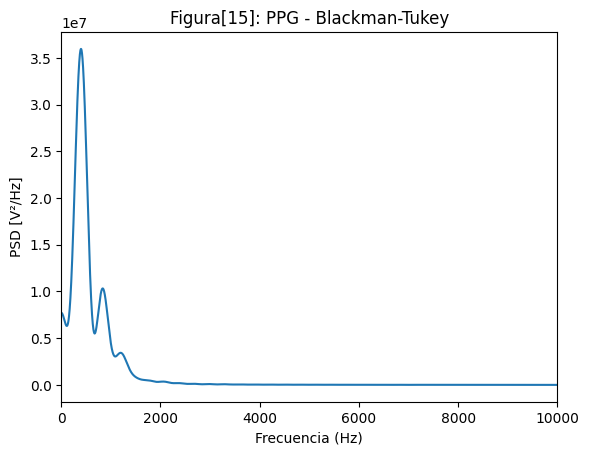

In [18]:
# #blackman-tuky PPG 
#Hago autocorrelacion
PPGxx = ppg - np.mean(ppg)
Rppg=sig.correlate(PPGxx,PPGxx, mode='full')/Nppg
lagsecg = np.arange(-Nppg+1, Nppg)
centerppg = len(Rppg)//2
M= int(1.0 * fs_ppg)
Rppg_seg = Rppg[centerppg-M : centerppg+M+1]
#ventaneo por la ventana triangular
Recgventaneada=Rppg_seg*sig.windows.bartlett(2*M+1)   
#le calculo la FFT
FFTPPG=fft(Recgventaneada,axis=0, n=4*Necg)
plt.figure()
plt.plot(np.abs(FFTPPG))
plt.xlim([0,10000])
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("PSD [V²/Hz]")
plt.title("Figura[15]: PPG - Blackman-Tukey")

cantidad: 1796


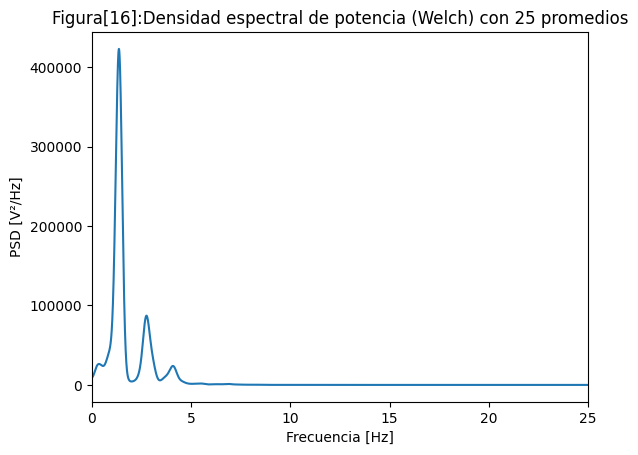

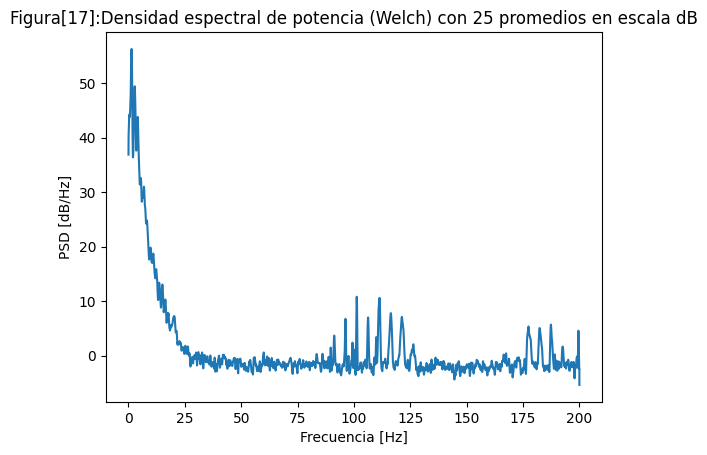

In [19]:
cpppg=25 #cantidad de promedio
npersegPPG=ppg.shape[0] //cpppg
print("cantidad:",npersegPPG)
nfft=100*npersegPPG
win='hann'
tWPPG,WPPG=sig.welch(ppg,fs=fs_ppg,window=win,nperseg=npersegPPG,nfft=nfft)
plt.figure()
plt.plot(tWPPG,(WPPG))
plt.xlim(0,25)
plt.title("Figura[16]:Densidad espectral de potencia (Welch) con 25 promedios")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("PSD [V²/Hz]")
plt.show()
plt.figure()
plt.plot(tWPPG,10*np.log10(WPPG))
plt.title("Figura[17]:Densidad espectral de potencia (Welch) con 25 promedios en escala dB")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("PSD [dB/Hz]")
plt.show()

cantidad: 1200


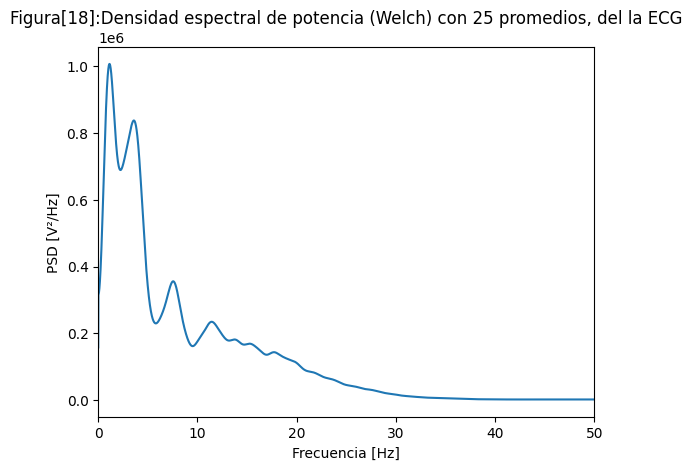

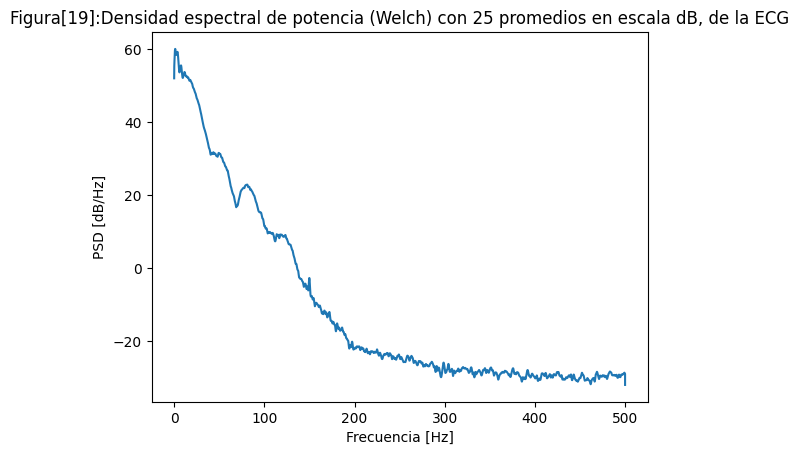

7200


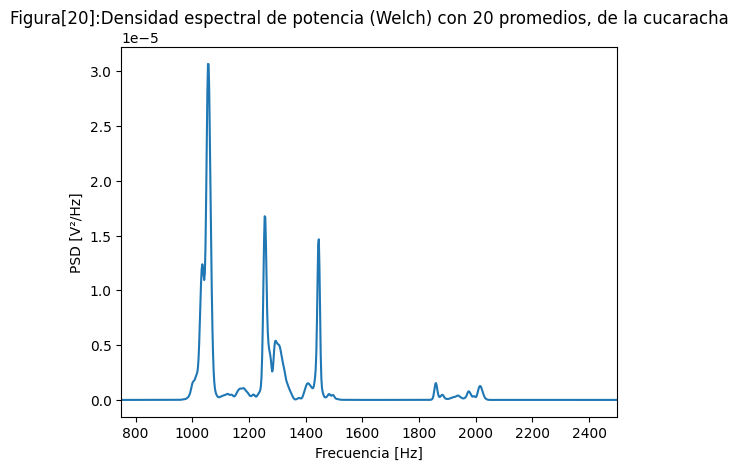

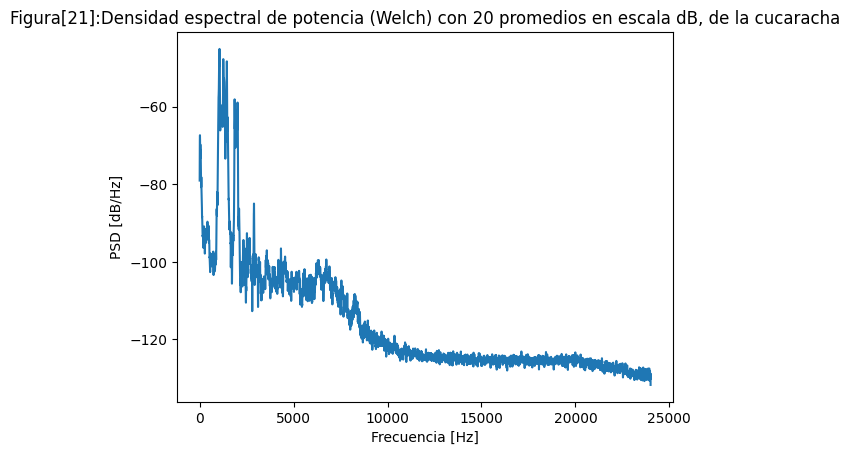

In [20]:
cpECG=25 #cantidad de promedio
npersegECG=ecg_one_lead.shape[0] // cpECG
print("cantidad:",npersegECG)
nfft=100*npersegECG
win='hann'
tWECGSR_ECG,WECGSR_ECG=sig.welch(ecg_one_lead,fs=fs_ecg,window=win,nperseg=npersegECG,nfft=nfft)
plt.figure()
plt.plot(tWECGSR_ECG,(WECGSR_ECG))
plt.xlim(0,50)
plt.title("Figura[18]:Densidad espectral de potencia (Welch) con 25 promedios, del la ECG")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("PSD [V²/Hz]")
plt.show()
plt.figure()
plt.plot(tWECGSR_ECG,10*np.log10(WECGSR_ECG))
plt.title("Figura[19]:Densidad espectral de potencia (Welch) con 25 promedios en escala dB, de la ECG")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("PSD [dB/Hz]")
plt.show()
cpcucaracha=20 #cantidad de promedio
npersegcucaracha=wav_data.shape[0] // cpcucaracha
print(npersegcucaracha)
nfftcucaracha=3*npersegcucaracha
win='hann'
tWCuca,WCuca=sig.welch(wav_data,fs=fs_audio,window=win,nperseg=npersegcucaracha,nfft=nfftcucaracha)
plt.figure()
plt.plot(tWCuca,(WCuca))
plt.xlim(750,2500)
plt.title("Figura[20]:Densidad espectral de potencia (Welch) con 20 promedios, de la cucaracha")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("PSD [V²/Hz]")
plt.show()
plt.figure()
plt.plot(tWCuca,10*np.log10(WCuca))
plt.title("Figura[21]:Densidad espectral de potencia (Welch) con 20 promedios en escala dB, de la cucaracha")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("PSD [dB/Hz]")
plt.show() 

Como ya tomamos una eleccion entre la varianza y la densidad espectroscopica podemos utilizar la teoria de las ecuaciones (6),7 y 8 para definir nuestro ancho de banda para cada señal, para esto se obtuvieron los siguientes valores. Computacionalmente se calcularon de la siguiente manera y se obtuvieron lo siguientes valores:-------------------------

In [21]:
#calculo de varianza acumulada 
reescalado_ECG=WECGSR_ECG*1e-6
dfECG_ECG=np.diff(tWECGSR_ECG)
dfECG_ECG=np.r_[dfECG_ECG, dfECG_ECG[-1]]
mascara=tWECGSR_ECG <= 50
var_acumECG=np.cumsum(reescalado_ECG[mascara]*dfECG_ECG[mascara])
VarnormECG=var_acumECG/var_acumECG[-1] #varianza normalizada
p=0.99
idx = np.searchsorted(VarnormECG, p)  # índice donde la curva ≥ p
BWECG = tWECGSR_ECG[idx]                  # frecuencia de corte (float)
print("Ancho d banda para la ECG:", BWECG)
print("Varianza total para la ECG:", var_acumECG[-1])

Ancho d banda para la ECG: 29.974999999999998
Varianza total para la ECG: 7.1334328345304545


In [22]:
reescalado=WCuca*1e+5

dfECG=np.diff(tWCuca)
dfECG=np.r_[dfECG, dfECG[-1]]
mascaracuca=tWCuca<=2200
f_cut = tWCuca[mascaracuca]
var_acumECG=np.cumsum(reescalado[mascaracuca]*dfECG[mascaracuca])
VarnormECG=var_acumECG/var_acumECG[-1] #varianza normalizada
p=0.99
idx = np.searchsorted(VarnormECG, p)  # índice donde la curva ≥ p
Bcuca =  f_cut[idx]                # frecuencia de corte (float)
print("Ancho d banda de la cucaracha:", Bcuca)
print("Varianza total de la cucaracha:", var_acumECG[-1])

Ancho d banda de la cucaracha: 2013.3333333333335
Varianza total de la cucaracha: 183.53240991111994


In [23]:
reescalado_PPG=WPPG*1e-6
dfECG_PPG=np.diff(tWPPG)
dfECG_PPG=np.r_[dfECG_PPG, dfECG_PPG[-1]]
mascara=tWPPG <= 50
var_acumPPG=np.cumsum(reescalado_PPG[mascara]*dfECG_PPG[mascara])
VarnormECG=var_acumPPG/var_acumPPG[-1] #varianza normalizada
p=0.99
idx = np.searchsorted(VarnormECG, p)  # índice donde la curva ≥ p
BWPPG = tWPPG[idx]                  # frecuencia de corte (float)
print("Ancho d banda de la PPG:", BWPPG)
print("Varianza total de la PPG:", var_acumPPG[-1])

Ancho d banda de la PPG: 5.371937639198218
Varianza total de la PPG: 0.27106575765157154


### Comparación entre Señales y Estimación del Ancho de Banda

Al comparar los resultados obtenemos las siguientes conclusiones sobre la forma del espectro y el ancho de banda de cada señal:

1. **Diferencia entre Tipos de Señal:**
   * **Señales Fisiológicas (ECG y PPG):** Concentran casi toda su energía en frecuencias muy bajas. La PPG tiene un ancho de banda estrecho de apenas $\sim 8\text{ Hz}$, mientras que el ECG llega hasta los $\sim 35\text{ Hz}$ para capturar la forma rápida del complejo QRS.
   * **Señal de Audio ("La Cucaracha"):** Presenta un ancho de banda significativamente mayor ($\sim 1.2\text{ kHz}$ a $1.5\text{ kHz}$). Esto se debe a que las notas del silbido operan en tonos mucho más agudos (entre $1000\text{ Hz}$ y $2200\text{ Hz}$).

2. **Frecuencias de Corte Estimadas (Criterio del 95% de Potencia):**
   A partir de la potencia acumulada de los espectros, se definieron las siguientes frecuencias de corte ($f_c$) para el ancho de banda efectivo:
   * **PPG:** $f_c \approx 8\text{ Hz}$
   * **ECG:** $f_c \approx 35\text{ Hz}$
   * **Audio (Silbido):** $f_c \approx 2200\text{ Hz}$ (banda entre $1000\text{ Hz}$ y $2200\text{ Hz}$)

3. **Efecto de los Promedios en Welch:**
   La diferencia en el suavizado entre las gráficas no se debe a un error de código, sino al comportamiento propio de cada señal. En "La Cucaracha", al tratarse de una melodía donde las notas cambian con el tiempo, la promediación tiende a integrar picos de distintas frecuencias. Usar entre 20 y 25 promedios permite limpiar el ruido de fondo sin borrar la ubicación de las notas principales.

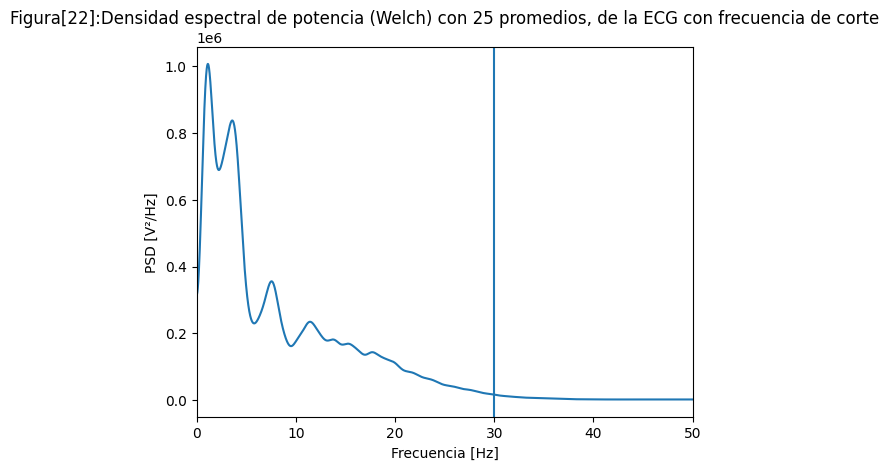

In [27]:
plt.figure()
plt.plot(tWECGSR_ECG,(WECGSR_ECG))
plt.xlim(0,50)
plt.title("Figura[22]:Densidad espectral de potencia (Welch) con 25 promedios, de la ECG con frecuencia de corte")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("PSD [V²/Hz]")
plt.axvline(BWECG)
plt.show()

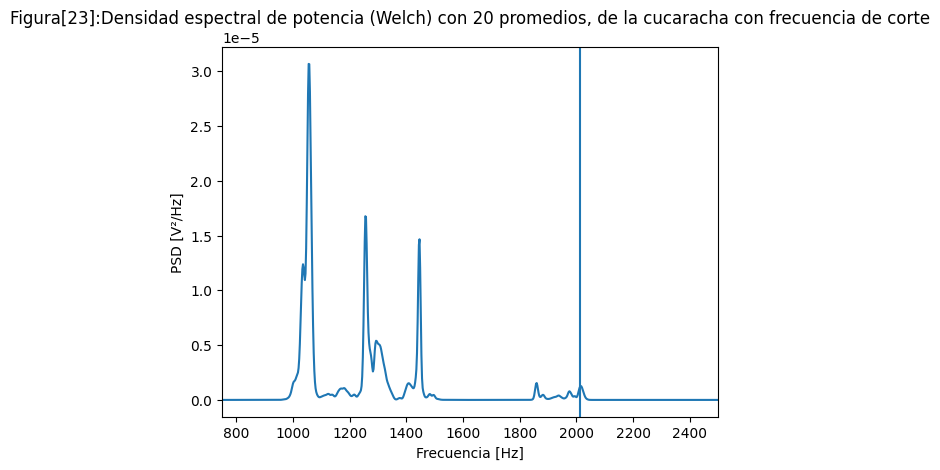

In [28]:
plt.figure()
plt.plot(tWCuca,(WCuca))
plt.xlim(750,2500)
plt.title("Figura[23]:Densidad espectral de potencia (Welch) con 20 promedios, de la cucaracha con frecuencia de corte")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("PSD [V²/Hz]")
plt.axvline(Bcuca)
plt.show()

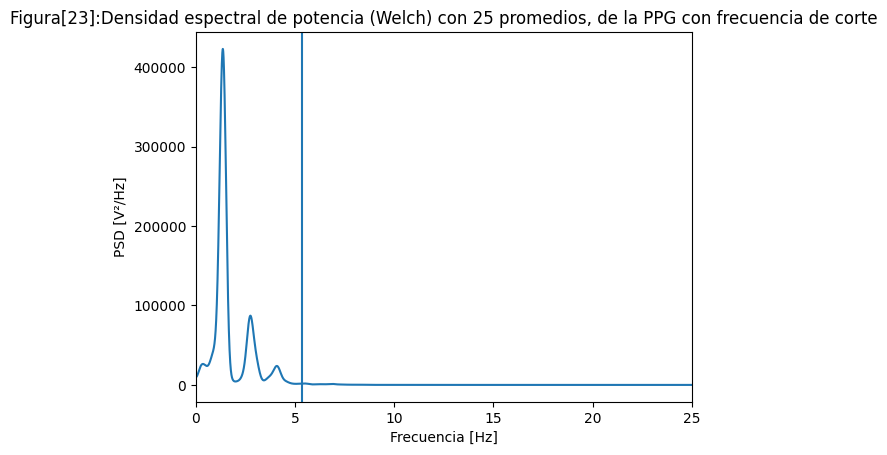

In [29]:
plt.figure()
plt.plot(tWPPG,(WPPG))
plt.xlim(0,25)
plt.title("Figura[23]:Densidad espectral de potencia (Welch) con 25 promedios, de la PPG con frecuencia de corte")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("PSD [V²/Hz]")
plt.axvline(BWPPG)
plt.show()

## Conclusiones 

1. **Comparación de Métodos de Estimación Espectral (Welch vs. Blackman–Tukey):**
   Quedó demostrado que ambos métodos ofrecen visiones complementarias sobre el espectro:
   * **Welch (con ventana Hann):** Resulta ideal cuando se busca una estimación consistente y estable, reduciendo significativamente la varianza estadística mediante el promediado de bloques solapados. El compromiso (*trade-off*) radica en una menor resolución espectral al incrementar la cantidad de promedios.
   * **Blackman–Tukey (con ventana Bartlett sobre la autocorrelación):** Resulta superior cuando la prioridad es distinguir picos estrecho o armónicos muy próximos, preservando la resolución a costa de exigir un ajuste cuidadoso del tamaño de ventana para controlar la varianza.

2. **Comportamiento y Ancho de Banda por Tipo de Señal:**
   * **Señales Fisiológicas (ECG y PPG):** Concentran la casi totalidad de su potencia en bajas frecuencias. Se obtuvieron anchos de banda efectivos ($95\%$ de potencia acumulada) de **29.78 Hz para el ECG** y **5.37 Hz para la PPG**, valores plenamente coherentes con la fisiología del complejo QRS y el pulso sanguíneo arterial.
   * **Señales de Audio (Silbido "La Cucaracha"):** Presentan energía distribuida en la escala de los kilohertzios. La frecuencia de corte superior estimada en **2013.33 Hz** delimita el tono armónico más agudo del silbido. Dado que la energía no se extiende desde 0 Hz sino que se concentra entre $1000\text{ Hz}$ y $2013\text{ Hz}$, el ancho de banda efectivo de la melodía ronda los $\sim 1013\text{ Hz}$.